In [502]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import os
import sys
import csv


In [503]:
# read sweeping data quadratic
base_path = "/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic"
vanilla_path = os.path.join(base_path,"vanilla","summary.csv")
vanilla_trajectory = pd.read_csv(vanilla_path)

In [504]:
# checking the data frame
pd.DataFrame(vanilla_trajectory)

,dataset,function,n_iter,converged,total_queries,final_obj,final_r,final_s,elapsed_s,rho,zeta,eps_abs,eps_rel,max_iters
0,homogeneous,quadratic,26,True,520,14.014477,0.000043,0.007786,0.011,10,1.0,0.000001,0.001,300
1,heterogeneous,quadratic,39,True,780,20.367219,0.000003,0.007175,0.015,10,1.0,0.000001,0.001,300
2,separated_2_clusters,quadratic,36,True,720,9.054387,0.000012,0.006107,0.014,10,1.0,0.000001,0.001,300
3,separated_3_clusters,quadratic,33,True,660,4.214800,0.000053,0.005176,0.013,10,1.0,0.000001,0.001,300
4,overlapping_2_clusters,quadratic,29,True,580,9.418574,0.000025,0.006541,0.011,10,1.0,0.000001,0.001,300
5,overlapping_3_clusters,quadratic,29,True,580,5.537274,0.000039,0.006557,0.011,10,1.0,0.000001,0.001,300


## Common

In [505]:
# read sweeping data for each scenario of the dataset

scenario = [
    "heterogeneous",
    "homogeneous",
    "overlapping_2_clusters",
    "overlapping_3_clusters",
    "separated_2_clusters",
    "separated_3_clusters",
]

# read the baseline as reference for the selecting dataset scenario
def load_vanilla_reference(base_path):

    vanilla = pd.read_csv(os.path.join(base_path, "vanilla", "summary.csv"))

    # Comparing against a non-converged baseline would make every rule meaningless.

    assert vanilla["converged"].all(), "vanilla ADMM did not converge on some dataset"

    cols = ["n_iter", "total_queries", "final_obj"]

    return vanilla.set_index("dataset")[cols].add_suffix("_vanilla")


vanilla_ref = load_vanilla_reference(base_path)
vanilla_ref


,n_iter_vanilla,total_queries_vanilla,final_obj_vanilla
dataset,,,
homogeneous,26,520,14.014477
heterogeneous,39,780,20.367219
separated_2_clusters,36,720,9.054387
separated_3_clusters,33,660,4.214800
overlapping_2_clusters,29,580,9.418574
overlapping_3_clusters,29,580,5.537274


In [506]:
## mapping the data of each row with the vanilla reference & compute the relative objective error and the communication saving percentage for each metho
## purpose: compare the performance of each method and choose the best setting for each method based on the relative obj err & the total queries

def add_vanilla_comparison(summary, vanilla_ref, method_path):

    # left join so no sweep run disappears silently; many_to_one catches duplicate baselines.
    
    df = summary.merge(vanilla_ref, left_on="dataset", right_index=True,
                       how="left", validate="many_to_one")
    
    assert df["n_iter_vanilla"].notna().all(), "some datasets have no vanilla baseline"

    # iteration rario to select the one that can be not too slow and not too fast than the Vanilla ADMM
    df["iter_ratio"] = df["n_iter"] / df["n_iter_vanilla"]

    # select the one that give the relative objective error in the range we consider is acceptable (0.01% or 0.05%)
    df["obj_rel_err_pct"] = (100 * (df["final_obj"] - df["final_obj_vanilla"]).abs()
                             / df["final_obj_vanilla"].abs())

    # less queries than the vanilla ADMM
    df["comm_saving_pct"] = 100 * (1 - df["total_queries"] / df["total_queries_vanilla"])
    
    # path.
    df["traj_file"] = df["traj_path"].map(lambda p: os.path.join(method_path, p))
    return df


## 1. Analyze the SOGP sweeping data

In [507]:
sogp_path = os.path.join(base_path, "sogp")
sogp_runs = add_vanilla_comparison(pd.read_csv(os.path.join(sogp_path, "summary.csv")),
                                   vanilla_ref, sogp_path)
sogp_runs[["dataset", "iota", "alpha", "n_iter", "iter_ratio",
           "obj_rel_err_pct", "comm_saving_pct", "traj_file"]].head()


,dataset,iota,alpha,n_iter,iter_ratio,obj_rel_err_pct,comm_saving_pct,traj_file
0,homogeneous,0.5,0.87,64,2.461538,0.001590,35.769231,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.87.json
1,homogeneous,0.5,0.86,60,2.307692,0.000661,33.269231,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.86.json
2,homogeneous,0.5,0.81,46,1.769231,0.001966,28.076923,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.81.json
3,homogeneous,0.5,0.80,44,1.692308,0.001739,27.692308,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.80.json
4,homogeneous,0.5,0.84,54,2.076923,0.000899,28.653846,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.84.json


In [508]:
sogp_runs

,run_id,method,function,dataset,iota,alpha,traj_path,burn_in,train_iter,lr,...,final_s,elapsed_s,error,n_iter_vanilla,total_queries_vanilla,final_obj_vanilla,iter_ratio,obj_rel_err_pct,comm_saving_pct,traj_file
0,homogeneous__iota0.50__alpha0.87,sogp,quadratic,homogeneous,0.5,0.87,homogeneous/trajectories/iota0.50__alpha0.87.json,5,100,0.01,...,0.008421,53.022,NaN,26,520,14.014477,2.461538,0.001590,35.769231,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.87.json
1,homogeneous__iota0.50__alpha0.86,sogp,quadratic,homogeneous,0.5,0.86,homogeneous/trajectories/iota0.50__alpha0.86.json,5,100,0.01,...,0.008555,54.735,NaN,26,520,14.014477,2.307692,0.000661,33.269231,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.86.json
2,homogeneous__iota0.50__alpha0.81,sogp,quadratic,homogeneous,0.5,0.81,homogeneous/trajectories/iota0.50__alpha0.81.json,5,100,0.01,...,0.008049,58.344,NaN,26,520,14.014477,1.769231,0.001966,28.076923,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.81.json
3,homogeneous__iota0.50__alpha0.80,sogp,quadratic,homogeneous,0.5,0.80,homogeneous/trajectories/iota0.50__alpha0.80.json,5,100,0.01,...,0.008228,58.783,NaN,26,520,14.014477,1.692308,0.001739,27.692308,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.80.json
4,homogeneous__iota0.50__alpha0.84,sogp,quadratic,homogeneous,0.5,0.84,homogeneous/trajectories/iota0.50__alpha0.84.json,5,100,0.01,...,0.007189,59.421,NaN,26,520,14.014477,2.076923,0.000899,28.653846,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.50__alpha0.84.json
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1315,overlapping_3_clusters__iota1.50__alpha0.95,sogp,quadratic,overlapping_3_clusters,1.5,0.95,overlapping_3_clusters/trajectories/iota1.50__alpha0.95.json,5,100,0.01,...,0.006993,53.869,NaN,29,580,5.537274,5.413793,0.007576,49.655172,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_3_clusters/trajectories/iota1.50__alpha0.95.json
1316,overlapping_3_clusters__iota1.50__alpha0.97,sogp,quadratic,overlapping_3_clusters,1.5,0.97,overlapping_3_clusters/trajectories/iota1.50__alpha0.97.json,5,100,0.01,...,0.064459,41.890,NaN,29,580,5.537274,6.896552,0.080528,58.620690,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_3_clusters/trajectories/iota1.50__alpha0.97.json
1317,overlapping_3_clusters__iota1.50__alpha0.98,sogp,quadratic,overlapping_3_clusters,1.5,0.98,overlapping_3_clusters/trajectories/iota1.50__alpha0.98.json,5,100,0.01,...,0.269507,33.016,NaN,29,580,5.537274,6.896552,0.937081,66.034483,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_3_clusters/trajectories/iota1.50__alpha0.98.json
1318,overlapping_3_clusters__iota1.50__alpha0.99,sogp,quadratic,overlapping_3_clusters,1.5,0.99,overlapping_3_clusters/trajectories/iota1.50__alpha0.99.json,5,100,0.01,...,0.139501,31.004,NaN,29,580,5.537274,6.896552,18.112253,71.206897,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_3_clusters

In [509]:
## Filter to get the eligible setting. The eligible setting is considered as the one meet those setting

## 1. need to converge
## 2. max iter < 2 * n_admm
## 3. obj_rel_err_pct < 0.05
## 4. total queries < total_queries_vanilla

MAX_ITER_RATIO = 2
# MAX_ITER_RATIO = 3.0
OBJ_TOL_PCT = 0.01


IOTA_RANGE = (0.5, 1.5)
ALPHA_RANGE = (0.8, 0.99)


def in_range(values, value_range):
    """True where values lie in [low, high]; all True when no range is given."""
    if value_range is None:
        return pd.Series(True, index=values.index)
    low, high = value_range
    return values.between(low, high)

def apply_filter_rules(df, max_iter_ratio=MAX_ITER_RATIO, obj_tol_pct=OBJ_TOL_PCT,
                       iota_range=IOTA_RANGE, alpha_range=ALPHA_RANGE):

    df = df.copy()
    # filter 1
    df["ok_converged"] = (df["status"] == "ok") & df["converged"]

    # filter 2
    df["ok_speed"] = df["iter_ratio"] <= max_iter_ratio

    # filter 3
    df["ok_accuracy"] = df["obj_rel_err_pct"] <= obj_tol_pct

    # filter 4: numqueries < numqueries_vanilla
    df["ok_queries"] = df["total_queries"] < df["total_queries_vanilla"]

    # filter 5: restrict the search to the chosen (iota, alpha) window
    df["ok_grid"] = in_range(df["iota"], iota_range) & in_range(df["alpha"], alpha_range)

    # a run is valid only if it passes all the filters
    df["valid"] = df[["ok_converged", "ok_speed", "ok_accuracy",
                      "ok_queries", "ok_grid"]].all(axis=1)
    return df

In [510]:
# filter the sogp runs
sogp_runs = apply_filter_rules(sogp_runs)
sogp_runs.groupby("dataset")["valid"].sum()

dataset
heterogeneous             80
homogeneous               32
overlapping_2_clusters    32
overlapping_3_clusters    43
separated_2_clusters      70
separated_3_clusters      59
Name: valid, dtype: int64

In [511]:
## Based on the selected eligible setting, we can choose the best setting as the one provide the largest communication saving

BEST_COLS = ["dataset", "iota", "alpha",
             "n_iter", "n_iter_vanilla",
             "total_queries", "total_queries_vanilla",
             "comm_saving_pct", "obj_rel_err_pct", "traj_file"]


def select_best_per_scenario(df, scenarios):

    ranked = df[df["valid"]].sort_values(
        ["total_queries", "obj_rel_err_pct", "n_iter", "iota", "alpha"])
    
    best = ranked.groupby("dataset").head(1).set_index("dataset")

    # A scenario that was swept but has no valid run should be reported, not vanish.
    swept = set(df["dataset"])
    missing = [s for s in scenarios if s in swept and s not in best.index]

    if missing:
        print(f"WARNING: no valid run for {missing}")

    order = [s for s in scenarios if s in best.index]
    return best.loc[order].reset_index()[BEST_COLS]


In [512]:
pd.set_option("display.max_colwidth", None)  # show the full trajectory path

sogp_best = select_best_per_scenario(sogp_runs, scenario)
sogp_best.round({"comm_saving_pct": 1, "obj_rel_err_pct": 5})

,dataset,iota,alpha,n_iter,n_iter_vanilla,total_queries,total_queries_vanilla,comm_saving_pct,obj_rel_err_pct,traj_file
0,heterogeneous,0.6,0.88,71,39,347,780,55.5,0.00249,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/heterogeneous/trajectories/iota0.60__alpha0.88.json
1,homogeneous,0.7,0.83,52,26,355,520,31.7,0.00057,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/homogeneous/trajectories/iota0.70__alpha0.83.json
2,overlapping_2_clusters,0.7,0.83,58,29,441,580,24.0,0.00085,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_2_clusters/trajectories/iota0.70__alpha0.83.json
3,overlapping_3_clusters,1.3,0.83,58,29,376,580,35.2,0.00929,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/overlapping_3_clusters/trajectories/iota1.30__alpha0.83.json
4,separated_2_clusters,1.1,0.86,72,36,441,720,38.7,0.00191,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/separated_2_clusters/trajectories/iota1.10__alpha0.86.json
5,separated_3_clusters,1.3,0.84,64,33,390,660,40.9,0.00588,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/sogp/separated_3_clusters/trajectories/iota1.30__alpha0.84.json


## 2. Cluster MTGP sweeping data with Unconstrain Noise

In [513]:
## cluster MTGP

cluster_mtgp_path = os.path.join(base_path, "unconstrained_noise", "cluster_mtgp")

cluster_mtgp_runs = add_vanilla_comparison(pd.read_csv(os.path.join(cluster_mtgp_path, "summary.csv")),
                                   vanilla_ref, cluster_mtgp_path)

cluster_mtgp_runs[["dataset", "iota", "alpha", "n_iter", "iter_ratio",
           "obj_rel_err_pct", "comm_saving_pct", "traj_file"]].head()

,dataset,iota,alpha,n_iter,iter_ratio,obj_rel_err_pct,comm_saving_pct,traj_file
0,separated_2_clusters,0.5,0.81,36,1.0,1.498482e-06,17.222222,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota0.50__alpha0.81.json
1,separated_2_clusters,0.5,0.80,36,1.0,2.077978e-06,15.416667,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota0.50__alpha0.80.json
2,separated_2_clusters,0.5,0.83,36,1.0,7.220308e-07,21.388889,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota0.50__alpha0.83.json
3,separated_2_clusters,0.5,0.82,36,1.0,9.867490e-07,19.583333,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota0.50__alpha0.82.json
4,separated_2_clusters,0.5,0.85,36,1.0,1.873381e-06,27.777778,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota0.50__alpha0.85.json


In [514]:
cluster_mtgp_runs.shape

(880, 37)

In [515]:
# filter the cluster_mtgp runs
cluster_mtgp_runs = apply_filter_rules(cluster_mtgp_runs)
cluster_mtgp_runs.groupby("dataset")["valid"].sum()

dataset
overlapping_2_clusters    167
overlapping_3_clusters    130
separated_2_clusters      180
separated_3_clusters      167
Name: valid, dtype: int64

In [516]:
pd.set_option("display.max_colwidth", None)  # show the full trajectory path

cluster_mtgp_best = select_best_per_scenario(cluster_mtgp_runs, scenario)
cluster_mtgp_best.round({"comm_saving_pct": 1, "obj_rel_err_pct": 5})

,dataset,iota,alpha,n_iter,n_iter_vanilla,total_queries,total_queries_vanilla,comm_saving_pct,obj_rel_err_pct,traj_file
0,overlapping_2_clusters,0.7,0.95,48,29,153,580,73.6,0.00628,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/overlapping_2_clusters/trajectories/iota0.70__alpha0.95.json
1,overlapping_3_clusters,1.5,0.95,55,29,138,580,76.2,0.00629,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/overlapping_3_clusters/trajectories/iota1.50__alpha0.95.json
2,separated_2_clusters,1.4,0.96,71,36,155,720,78.5,0.00523,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_2_clusters/trajectories/iota1.40__alpha0.96.json
3,separated_3_clusters,1.5,0.96,61,33,140,660,78.8,0.00868,/home/delta/Documents/Comm_Efficient_MTGP_ADMM/Communication-Efficient-ADMM-using-Multitask-Gaussian-Processes/results/20 Agents Quadratic/unconstrained_noise/cluster_mtgp/separated_3_clusters/trajectories/iota1.50__alpha0.96.json


## 4. Plotting the trajectory and query dynamic

In [517]:
import json

# Same colorblind-safe colours and labels as the ICC figures, so plots stay comparable.
METHOD_COLORS = {
    "vanilla": "#5B5B5B",
    "sogp": "#0072B2",
    "global_mtgp": "#D55E00",
    "cluster_mtgp": "#009E73",
}
METHOD_LABELS = {
    "vanilla": "Vanilla ADMM",
    "sogp": "SOGP-ADMM",
    "global_mtgp": "Global MTGP-ADMM",
    "cluster_mtgp": "Cluster-wise MTGP-ADMM",
}

BURN_IN = 5  # iterations 0..4 always query; the first GP decision is at iteration 5

# Repo root is two levels above results/quadratic; the datasets live in data_generation/.
REPO_ROOT = os.path.dirname(os.path.dirname(base_path))
DATA_DIR = os.path.join(REPO_ROOT, "data_generation")

# Selected settings (from the *_best tables above), keyed by method.
# BEST_TABLES = {
#     "sogp": sogp_best,
#     "global_mtgp": global_mtgp_best,
#     "cluster_mtgp": cluster_mtgp_best,
# }

BEST_TABLES = {
    "sogp": sogp_best,
    "cluster_mtgp": cluster_mtgp_best,
}


def load_cluster_labels(dataset):
    """Cluster label of each agent, used to draw cluster boundaries in the plots."""
    with open(os.path.join(DATA_DIR, f"{dataset}.json")) as f:
        return np.asarray(json.load(f)["labels"])


def load_selected_runs(dataset, best_tables=BEST_TABLES):
    """Selected row + trajectory per method for one dataset: {method: {"row", "traj"}}."""
    runs = {}
    for method, best in best_tables.items():
        rows = best[best["dataset"] == dataset]
        if rows.empty:  # e.g. cluster MTGP was not run on the K=1 datasets
            continue
        row = rows.iloc[0]
        with open(row["traj_file"]) as f:
            traj = json.load(f)
        # Guard against a trajectory that doesn't belong to this summary row.
        mask = np.asarray(traj["comm_mask_per_iter"], dtype=bool)
        assert len(mask) == row["n_iter"], f"{method}: iteration count mismatch"
        assert mask.sum() == row["total_queries"], f"{method}: query count mismatch"
        runs[method] = {"row": row, "traj": traj}
    return runs


In [521]:
PLOT_DATASETS = ["overlapping_3_clusters", "separated_3_clusters"]

selected = {ds: load_selected_runs(ds) for ds in PLOT_DATASETS}
labels = {ds: load_cluster_labels(ds) for ds in PLOT_DATASETS}

for ds in PLOT_DATASETS:
    print(ds, "labels:", labels[ds])
    for method, run in selected[ds].items():
        r = run["row"]
        print(f"  {method:13s} iota={r['iota']} alpha={r['alpha']} "
              f"n_iter={r['n_iter']} queries={r['total_queries']}")


overlapping_3_clusters labels: [0 0 0 0 1 1 1 2 2 2]
  sogp          iota=1.3 alpha=0.83 n_iter=58 queries=376
  cluster_mtgp  iota=1.5 alpha=0.95 n_iter=55 queries=138
separated_3_clusters labels: [0 0 0 0 1 1 1 2 2 2]
  sogp          iota=1.3 alpha=0.84 n_iter=64 queries=390
  cluster_mtgp  iota=1.5 alpha=0.96 n_iter=61 queries=140


In [522]:
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

QUERY_BG = "#F7F7F7"  # light grey for "no query", so only query cells carry the method colour


def plot_query_heatmap(runs, dataset, methods=("sogp", "global_mtgp", "cluster_mtgp"), save_path=None):
    """Agent x iteration map of exact queries, one panel per method (ICC figure style)."""
    methods = [m for m in methods if m in runs]
    fig, axes = plt.subplots(len(methods), 1, figsize=(8.4, 3.0 * len(methods) + 0.9), squeeze=False)

    for ax, method in zip(axes[:, 0], methods):
        
        row, traj = runs[method]["row"], runs[method]["traj"]

        # comm in each iteration of 10 agents, its boolean array => True if agent queries, False otherwise
        mask = np.asarray(traj["comm_mask_per_iter"], dtype=bool).T   # (agents, iterations)

        # number of iteration and number of agents as maks is a big array shape (agents, iterations)
        n_agents, n_k = mask.shape

        # Each panel spans only its own run, so there is no empty area after convergence.
        ax.imshow(mask, aspect="auto", interpolation="nearest",
                  cmap=ListedColormap([QUERY_BG, METHOD_COLORS[method]]), vmin=0, vmax=1,
                  extent=(0.5, n_k + 0.5, n_agents + 0.5, 0.5))   # agent 1 on top, iterations 1..n_k
        ax.set_yticks(np.arange(1, n_agents + 1))
        ax.set_ylabel("Agent")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))

        # Faint row separators keep agents readable without breaking up the blocks.
        for y in np.arange(1.5, n_agents + 0.5):
            ax.axhline(y, color="#DDDDDD", linewidth=0.3)

        ax.set_title(METHOD_LABELS[method], loc="left", color=METHOD_COLORS[method],
                     fontsize=9.2, fontweight="semibold")
        ax.text(1.0, 1.02, f"Iterations={row['n_iter']}, exact queries={row['total_queries']}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8.2, color="#3A3A3A")

    axes[-1, 0].set_xlabel("ADMM iteration")
    fig.suptitle(f"Exact-query decisions — Quadratic, {dataset.replace('_', ' ')}", fontsize=10.5)
    fig.tight_layout(rect=(0, 0, 1, 0.96))

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig


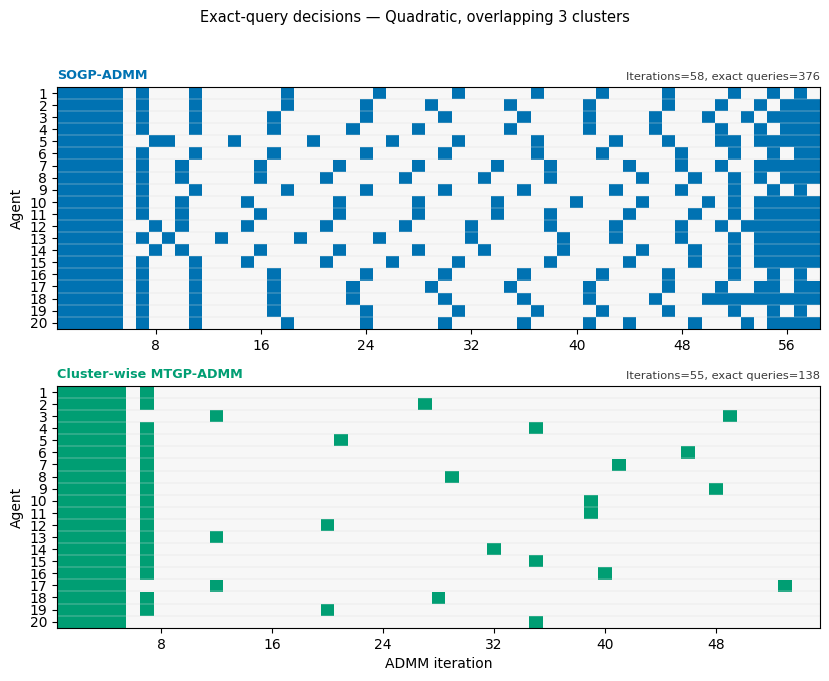

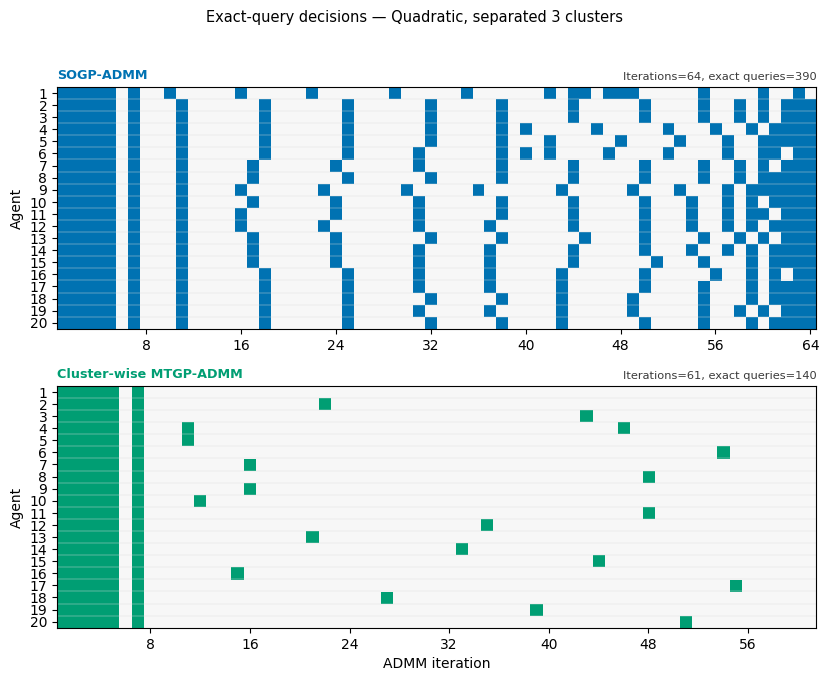

In [523]:
FIG_DIR = os.path.join(REPO_ROOT, "analysis", "figures", "20_agents_quadratic")

for ds in PLOT_DATASETS:
    plot_query_heatmap(selected[ds], ds, methods=["sogp", "cluster_mtgp"])
    # to save: plot_query_heatmap(selected[ds], ds, save_path=os.path.join(FIG_DIR, ds, "query_heatmap.png"))
    plt.show()


In [39]:
def mean_var_and_threshold(traj, start_iter=BURN_IN):
    """Mean across agents of the gate inputs, from the first GP decision onward.

    Returns (iterations, var_mean, psi_mean). var is each agent's max predictive
    variance (var_max) and psi its query threshold psi_i^k; an agent queries when
    var_max > psi. Iterations are 1-based to line up with the query heatmap.
    """
    stats = traj["stats_per_iter"][start_iter:]
    # NaN for any agent without GP stats at an iteration, so it drops out of the mean.
    var = np.array([[s.get("var_max", np.nan) for s in agents] for agents in stats])
    psi = np.array([[s.get("psi_k", np.nan) for s in agents] for agents in stats])
    iterations = np.arange(start_iter, start_iter + len(stats)) + 1
    return iterations, np.nanmean(var, axis=1), np.nanmean(psi, axis=1)


In [40]:
for ds in PLOT_DATASETS:
    for method in ("global_mtgp", "cluster_mtgp"):
        it, v, p = mean_var_and_threshold(selected[ds][method]["traj"])
        iota = selected[ds][method]["row"]["iota"]
        print(f"{ds:24s} {method:13s} first iter={it[0]}, n={len(it)}, "
              f"psi/var at start={p[0] / v[0]:.3f} (iota={iota})")


overlapping_3_clusters   global_mtgp   first iter=6, n=30, psi/var at start=1.000 (iota=1.0)
overlapping_3_clusters   cluster_mtgp  first iter=6, n=44, psi/var at start=1.000 (iota=1.0)
separated_3_clusters     global_mtgp   first iter=6, n=44, psi/var at start=1.000 (iota=1.0)
separated_3_clusters     cluster_mtgp  first iter=6, n=54, psi/var at start=0.800 (iota=0.8)


In [41]:
def plot_var_threshold(runs, dataset, methods=("cluster_mtgp", "global_mtgp"), save_path=None):
    """Mean max predictive variance (solid) vs mean query threshold psi (dashed), per MTGP method."""
    short_names = {"global_mtgp": "Global", "cluster_mtgp": "Cluster-wise"}
    fig, ax = plt.subplots(figsize=(7.2, 4.4))

    for method in methods:
        if method not in runs:
            continue
        iterations, var_mean, psi_mean = mean_var_and_threshold(runs[method]["traj"])
        color, name = METHOD_COLORS[method], short_names[method]
        # Same colour per method; line style separates the variance from its threshold.
        ax.plot(iterations, var_mean, color=color, linewidth=2,
                label=f"{name} mean max variance")
        ax.plot(iterations, psi_mean, color=color, linewidth=2, linestyle="--",
                label=rf"{name} mean $\psi_i^k$")

    ax.set_yscale("log")   # psi decays geometrically (alpha^k), so it is a straight line here
    ax.set_xlabel("ADMM iteration")
    ax.set_ylabel("Mean across agents (log scale)")
    ax.set_title(f"Mean predictive variance and query threshold — Quadratic, "
                 f"{dataset.replace('_', ' ')}", fontsize=10.5)
    ax.grid(True, which="both", axis="y", alpha=0.25)
    ax.grid(True, which="major", axis="x", alpha=0.25)
    ax.legend(fontsize=8.5)
    fig.tight_layout()

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig


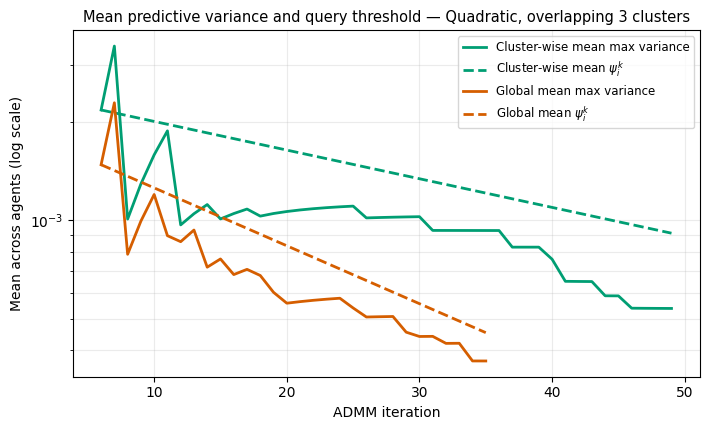

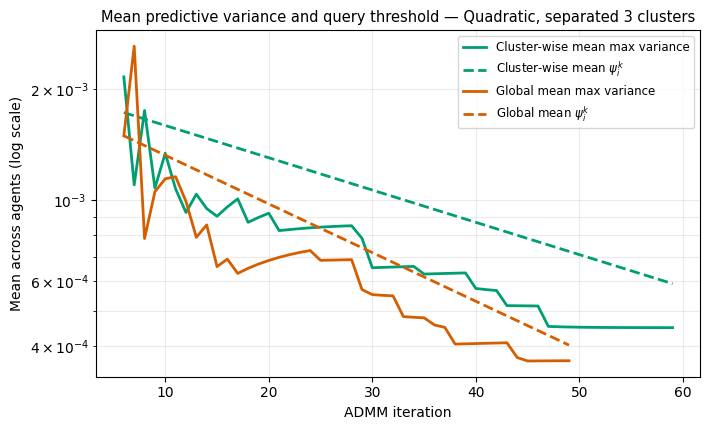

In [42]:
for ds in PLOT_DATASETS:
    plot_var_threshold(selected[ds], ds)
    # to save: plot_var_threshold(selected[ds], ds, save_path=os.path.join(FIG_DIR, ds, "variance_threshold.png"))
    plt.show()